# Step 10a · Regression: predicting dissolved oxygen (Q10)

**Problem (brief §15):** predict a continuous parameter, **dissolved oxygen (mg/L)**, for a site-day, from co-measured parameters, place and time.
**Why DO?** It has the highest exceedance rate (18%), and Step 3 showed a strong physical link with temperature (Spearman −0.63).
**Data:** site-day table from `WaterQualityAnalyticsMart` (built from the batch DW). **Features:** the Step 4 consensus selection.

**Validation (leakage-safe for time data):** **chronological split**, train on Jan 2024 – Jun 2025 and test on **Jul – Dec 2025**. The "previous DO" feature uses only the site's *earlier* sampling day, so nothing from the future is used.

| Model | Why |
|---|---|
| Simple linear regression (DO ~ temperature) | One meaningful predictor, the physics baseline |
| Multiple linear regression | All selected features; interpretable coefficients |
| Ridge, Lasso | Linear models that shrink coefficients (handle overlap between features / avoid overfitting) |
| Random Forest, Gradient Boosting | Non-linear models, as an academically justified extension |

**Metrics:**
- **MAE:** average absolute error, in mg/L
- **MSE:** average squared error
- **RMSE:** like MAE, but punishes big errors more, in mg/L
- **R²:** share of DO variation explained (1 = perfect)

In [1]:
import sys, time, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
ROOT = Path.cwd().resolve()
for p in [ROOT, *ROOT.parents]:
    if (p / '09_mining' / 'mining_data.py').exists(): ROOT = p; break
sys.path.insert(0, str(ROOT / '09_mining')); import mining_data as md_
OUT = ROOT / '09_mining'; FIG, TAB = OUT / 'figures', OUT / 'tables'; FIG.mkdir(exist_ok=True); TAB.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid'); pd.set_option('display.width', 200)
def save_tab(df, n, index=False): df.to_csv(TAB / f'R{n}.csv', index=index); return df
def save_fig(n): plt.tight_layout(); plt.savefig(FIG / f'R{n}.png', dpi=130, bbox_inches='tight'); plt.show()
SEL = md_.SELECTED['regression']['selected']; print('Features from Step 4:', SEL)
con = md_.connect(); df = md_.regression_table(con)
NUM = [f for f in SEL if f in ['temperature', 'ph', 'log_conductivity', 'log_turbidity', 'log_nitrate', 'prev_do', 'latitude', 'month_sin', 'month_cos']]
CAT = [f for f in SEL if f in ['season', 'region', 'state', 'water_type', 'sample_type_group', 'equipment_group']]
for c in NUM:
    base = c.replace('log_', '')
    if df[c].isna().any(): df[f'has_{base}'] = df[c].notna().astype(int); df[c] = df[c].fillna(df[c].median())
HAS = [c for c in df.columns if c.startswith('has_')]
X = pd.concat([df[NUM + HAS], pd.get_dummies(df[CAT].fillna('Unknown'), drop_first=True, dtype=float)], axis=1)
y = df.do_val.values; d = pd.to_datetime(df.sample_date); tr, te = d < '2025-07-01', d >= '2025-07-01'
print(f'Site-days: {len(df):,} · train {tr.sum():,} (Jan 2024–Jun 2025) · test {te.sum():,} (Jul–Dec 2025) · features {X.shape[1]}')

Features from Step 4: ['latitude', 'temperature', 'prev_do', 'ph', 'water_type', 'month_sin', 'month_cos', 'season', 'region']


Site-days: 300,762 · train 242,429 (Jan 2024–Jun 2025) · test 58,333 (Jul–Dec 2025) · features 27


## 1 · Fit all models and compare on the unseen test months

,Train R²,Test R²,Test MAE,Test MSE,Test RMSE,Seconds
Model,,,,,,
Simple linear (temperature only),0.3579,0.2034,1.7368,5.9156,2.4322,0.1243
Multiple linear,0.5928,0.5096,1.3703,3.6413,1.9082,0.2863
Ridge,0.5928,0.5096,1.3703,3.6413,1.9082,1.3154
Lasso,0.5925,0.5088,1.3715,3.6475,1.9098,1.9484
Random Forest,0.7921,0.6313,1.1503,2.7378,1.6546,67.2415
Gradient Boosting,0.7405,0.6389,1.1496,2.6811,1.6374,17.2806


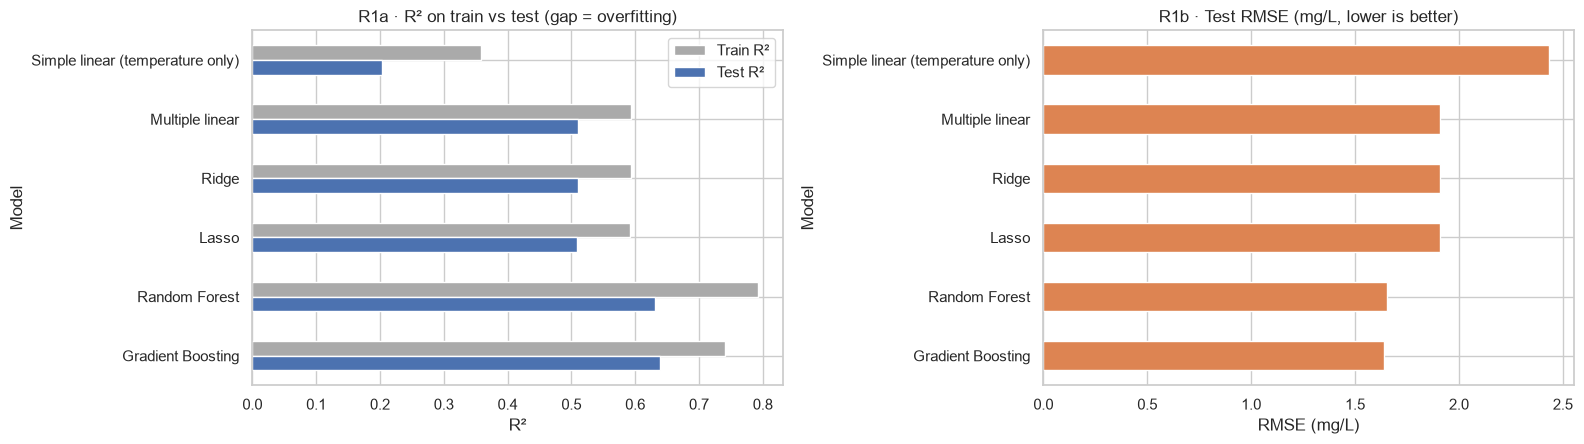

In [2]:
sc = StandardScaler().fit(X[tr]); Xs_tr, Xs_te = sc.transform(X[tr]), sc.transform(X[te])
models = {'Simple linear (temperature only)': ('lin1', LinearRegression()), 'Multiple linear': ('lin', LinearRegression()),
          'Ridge': ('lin', RidgeCV(alphas=np.logspace(-3, 3, 13))), 'Lasso': ('lin', LassoCV(cv=5, random_state=42, alphas=30)),
          'Random Forest': ('raw', RandomForestRegressor(n_estimators=200, max_depth=18, min_samples_leaf=10, n_jobs=-1, random_state=42)),
          'Gradient Boosting': ('raw', HistGradientBoostingRegressor(max_iter=400, learning_rate=0.08, random_state=42))}
res, preds, fitted = [], {}, {}
for name, (kind, m) in models.items():
    t = time.time()
    if kind == 'lin1': A_tr, A_te = df.loc[tr, ['temperature']].values, df.loc[te, ['temperature']].values
    elif kind == 'lin': A_tr, A_te = Xs_tr, Xs_te
    else: A_tr, A_te = X[tr].values, X[te].values
    m.fit(A_tr, y[tr]); p_tr, p_te = m.predict(A_tr), m.predict(A_te); preds[name] = p_te; fitted[name] = m
    res.append({'Model': name, 'Train R²': r2_score(y[tr], p_tr), 'Test R²': r2_score(y[te], p_te), 'Test MAE': mean_absolute_error(y[te], p_te),
                'Test MSE': mean_squared_error(y[te], p_te), 'Test RMSE': mean_squared_error(y[te], p_te) ** 0.5, 'Seconds': time.time() - t})
res = pd.DataFrame(res).set_index('Model'); display(save_tab(res.round(4), '01_model_comparison', index=True))
fig, axes = plt.subplots(1, 2, figsize=(16, 4.6))
res[['Train R²', 'Test R²']].plot(kind='barh', ax=axes[0], color=['#AAAAAA', '#4C72B0']); axes[0].set(title='R1a · R² on train vs test (gap = overfitting)', xlabel='R²')
res['Test RMSE'].plot(kind='barh', ax=axes[1], color='#DD8452'); axes[1].set(title='R1b · Test RMSE (mg/L, lower is better)', xlabel='RMSE (mg/L)')
for ax in axes: ax.invert_yaxis()
save_fig('01_model_comparison')

**Why these charts:** the left chart compares how well each model fits the data it learned from and the unseen months (a large gap = overfitting); the right chart shows the typical prediction error in mg/L.

**🔎 Inference (R1): model comparison on unseen months (Jul–Dec 2025)**
- **Simple linear regression (DO ~ temperature)** explains **R² = 0.20** of DO on the test months (RMSE 2.43 mg/L). Temperature alone is a real but incomplete predictor.
- **Multiple linear regression** with the Step 4 features reaches **R² = 0.51** (RMSE **1.91 mg/L**, MAE 1.37). Adding previous DO, pH, latitude, season and water type more than doubles the explained variation.
- **Ridge and Lasso give the same result as plain linear regression** (0.510 / 0.509). With 240K training rows and well-chosen, low-overlap features there is little overfitting for shrinkage to fix.
- **Non-linear models are best:** **Gradient Boosting R² = 0.64, RMSE 1.64 mg/L, MAE 1.15 mg/L**; Random Forest is close (0.63). DO depends on its predictors in curved and interacting ways (e.g. the temperature effect differs by region and season), which trees capture and straight lines cannot.
- **Overfitting check:** Random Forest scores **R² 0.79 on training vs 0.63 on test**, a clear gap. Gradient Boosting's gap is smaller (0.74 → 0.64) and it scores higher on test, so it **generalises best**.
- **In practice:** a typical prediction is within about **±1.1–1.6 mg/L** of the measured DO. That is good enough to flag likely low-oxygen site-days for checking (the threshold is 5 mg/L), but not a replacement for measurement.
- **Honest limitation:** all test months are in the second half of 2025, which contains more summer/autumn data than the training period, so performance is checked against a genuinely different season mix (a strict, leakage-safe test).

## 2 · Interpreting the multiple linear regression
Coefficients with **standardised** features show the effect of a one-standard-deviation change in each feature on DO (mg/L). The `statsmodels` OLS summary gives p-values. **VIF** checks multicollinearity, and the **Breusch–Pagan test** checks heteroscedasticity (does the error size change with the prediction?).

In [3]:
ols = sm.OLS(y[tr], sm.add_constant(pd.DataFrame(Xs_tr, columns=X.columns))).fit()
coef = pd.DataFrame({'coef (mg/L per 1 SD)': ols.params.drop('const'), 'p_value': ols.pvalues.drop('const')}).sort_values('coef (mg/L per 1 SD)', key=abs, ascending=False)
display(save_tab(coef.round(4).head(20), '02_linear_coefficients', index=True)); print(f'OLS train R² = {ols.rsquared:.3f}, adj. R² = {ols.rsquared_adj:.3f}')
vx = pd.DataFrame(Xs_tr[:50000], columns=X.columns)[NUM]
vif = pd.Series([variance_inflation_factor(sm.add_constant(vx).values, i + 1) for i in range(vx.shape[1])], index=NUM, name='VIF')
display(save_tab(vif.round(2).to_frame(), '03_vif', index=True))
bp = het_breuschpagan(ols.resid[:50000], sm.add_constant(pd.DataFrame(Xs_tr[:50000], columns=X.columns)))
print(f'Breusch–Pagan LM p-value = {bp[1]:.3g} -> {"heteroscedastic (error size varies)" if bp[1] < 0.05 else "no evidence of heteroscedasticity"}')

,coef (mg/L per 1 SD),p_value
water_type_Not Reported,2.9660,0.0000
water_type_Surface Water,2.7176,0.0000
prev_do,0.9304,0.0000
temperature,-0.9277,0.0000
ph,0.6407,0.0000
latitude,0.6351,0.0000
region_South,0.4160,0.0000
month_cos,0.2823,0.0000
water_type_Ocean Water,0.2019,0.0000
month_sin,0.1835,0.0000


OLS train R² = 0.593, adj. R² = 0.593


,VIF
latitude,3.75
temperature,3.99
prev_do,1.28
ph,1.03
month_sin,1.09
month_cos,1.98


Breusch–Pagan LM p-value = 0 -> heteroscedastic (error size varies)


C:\Users\sansk\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\stats\diagnostic.py:1217: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  resols = OLS(y, x).fit()


**🔎 Inference (R2): coefficients, multicollinearity and heteroscedasticity**
- **Strongest effects** (mg/L change in DO per 1-standard-deviation change, all p < 0.001):
  - **previous DO +0.93**: a site's oxygen level persists between visits
  - **temperature −0.93**: warmer water, less oxygen (physics)
  - **pH +0.64**: photosynthesis raises both
  - **latitude +0.64**: cooler northern waters
  - the South region and winter/spring seasons are slightly higher once temperature is accounted for
- The large coefficients for the **water-type dummies** (e.g. Surface Water +2.7 relative to the reference category) are measured against a *tiny* reference group (a rare water type). They mean "surface water has much more oxygen than that rare group", consistent with groundwater/effluent being low in oxygen. They should not be read as absolute effects.
- **Multicollinearity is acceptable:** VIF of temperature 4.0 and latitude 3.8 (they overlap: the south is warmer), all others < 2. Everything is below the warning level of 5, so the coefficients are stable.
- **Heteroscedasticity is present** (Breusch–Pagan p ≈ 0): errors are larger at some prediction levels (see R3). The linear coefficients stay unbiased, but their standard errors are optimistic. This is one more reason the tree-based models, which make no constant-variance assumption, are preferred for prediction.

## 3 · Residual diagnostics (best model vs multiple linear)

Best model on test months: Gradient Boosting


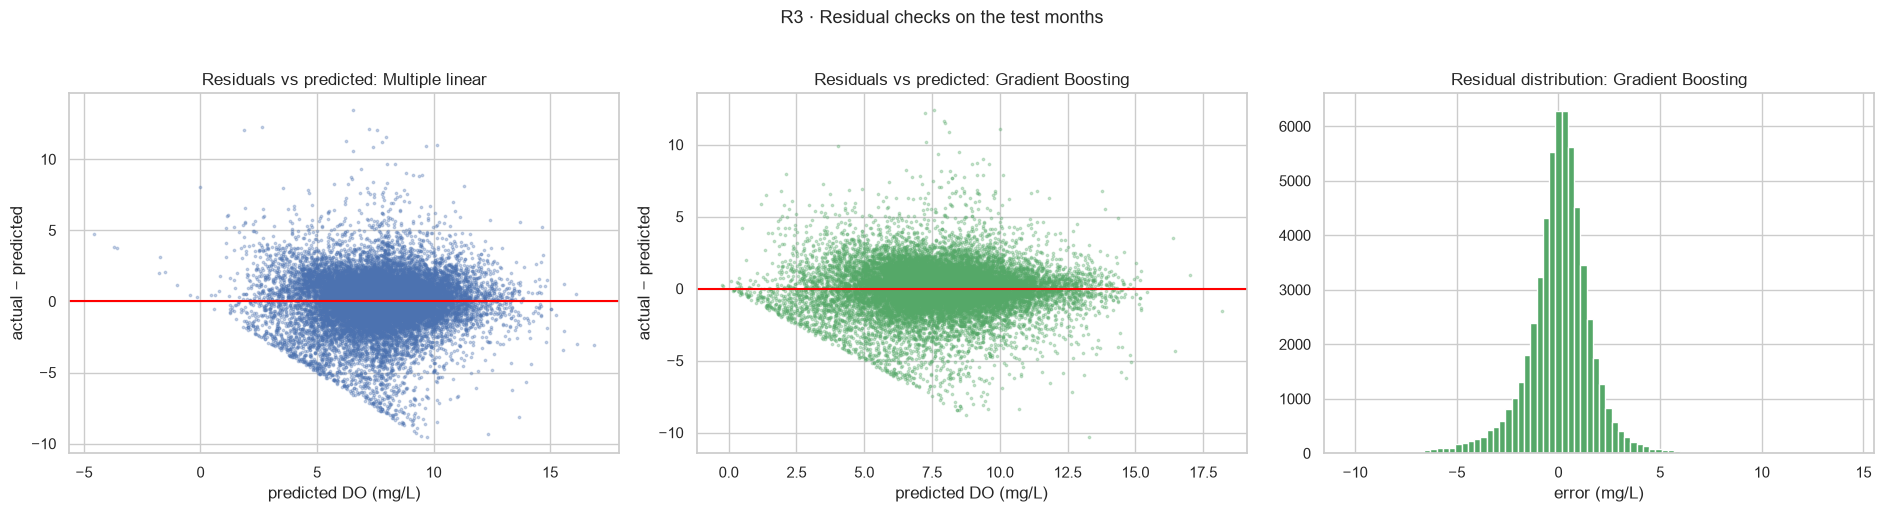

In [4]:
best = res['Test R²'].idxmax(); print('Best model on test months:', best)
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, name, col in [(axes[0], 'Multiple linear', '#4C72B0'), (axes[1], best, '#55A868')]:
    r_ = y[te] - preds[name]; s = np.random.default_rng(1).choice(len(r_), min(20000, len(r_)), replace=False)
    ax.scatter(preds[name][s], r_[s], s=3, alpha=0.3, color=col); ax.axhline(0, color='red')
    ax.set(title=f'Residuals vs predicted: {name}', xlabel='predicted DO (mg/L)', ylabel='actual − predicted')
axes[2].hist(y[te] - preds[best], bins=80, color='#55A868'); axes[2].set(title=f'Residual distribution: {best}', xlabel='error (mg/L)')
fig.suptitle('R3 · Residual checks on the test months', y=1.02, fontsize=13); save_fig('03_residuals')
if best in ('Random Forest',):
    imp = pd.Series(fitted[best].feature_importances_, index=X.columns).sort_values(ascending=False).head(15)
    display(save_tab(imp.rename('importance').to_frame(), '04_best_model_importance', index=True))

**Why these charts:** residuals (errors) should scatter evenly around zero. A funnel shape means heteroscedasticity, and a curve means the model misses a non-linear pattern. The histogram shows how big typical errors are and whether some are extreme (outliers).

**🔎 Inference (R3): residuals**
- **Multiple linear:** residuals fan out and curve. Errors are small for mid-range DO and larger at the extremes, so the straight-line model under-predicts very high (super-saturated) DO and over-predicts very low DO. This is the heteroscedasticity and non-linearity found above.
- **Gradient Boosting:** residuals are more evenly centred on zero across the range, with a narrower, roughly symmetric error distribution. Most errors fall within about ±2 mg/L, with a few large misses (outliers), mainly very low-oxygen site-days that are hard to predict from co-measured parameters alone.
- **Conclusion:** the non-linear model is the better predictor. The linear model remains useful for **explaining** direction and size of effects.
- **Limitations:** no flow, depth, weather or algae data are available in WQP results; sites without a previous DO value are predicted less accurately; and results are site-day medians.